In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils.DataLoader import DataLoader

from transformers import BertTokenizer, BertModel
from tqdm import tqdm
import torch


In [2]:
# dataloader = DataLoader(r'.\ctg-studies.json')
# df = dataloader.load_data()
# # df.head()
# df.to_csv(r'.\ctg-studies.csv', index=False)

In [3]:
df = pd.read_csv(r'.\ctg-studies.csv')
nctid_eligibility = df[['NCT ID', 'Eligibility Criteria']]
nctid_eligibility.head()

,NCT ID,Eligibility Criteria
0,NCT00019136,DISEASE CHARACTERISTICS:\r\n\r\n* Histological...
1,NCT00085930,Inclusion Criteria:\r\n\r\nHigh risk neuroblas...
2,NCT00881920,INCLUSION CRITERIA:\r\n\r\nBLOOD PROCUREMENT:\...
3,NCT00902044,INCLUSION CRITERIA:\r\n\r\nProcurement Eligibi...
4,NCT00924326,* INCLUSION CRITERIA:\r\n\r\n 1. Patient must...


In [5]:
tokenizer = BertTokenizer.from_pretrained("microsoft/BiomedNLP-BiomedBERT-large-uncased-abstract")
model = BertModel.from_pretrained("microsoft/BiomedNLP-BiomedBERT-large-uncased-abstract")


In [9]:
# Tokenize and get embeddings for each eligibility criteria
embeddings = []
for text in tqdm(nctid_eligibility['Eligibility Criteria']):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
    outputs = model(**inputs)
    pooled_output = torch.mean(outputs.last_hidden_state, dim=1)
    embeddings.append(pooled_output.detach().numpy())


# Flatten the embeddings
feature_matrix = [emb.flatten() for emb in embeddings]
pd.DataFrame(feature_matrix).to_csv(r'.\feature-matrix.csv', index=False)

  0%|          | 0/1267 [00:00<?, ?it/s]

100%|██████████| 1267/1267 [24:00:16<00:00, 68.21s/it]       


d:\opt\envs\clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
d:\opt\envs\clustering\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\Bhanuteja\AppData\Local\Temp\ipykernel_11472\966115002.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nctid_eligibility['Cluster_Labels'] = cluster_labels
d:\opt\envs\clustering\Lib\site-packages\seaborn\_oldcore.py:1498:

Cluster Labels:
Cluster_Labels
4    504
1    396
3    229
2    130
0      8
Name: count, dtype: int64


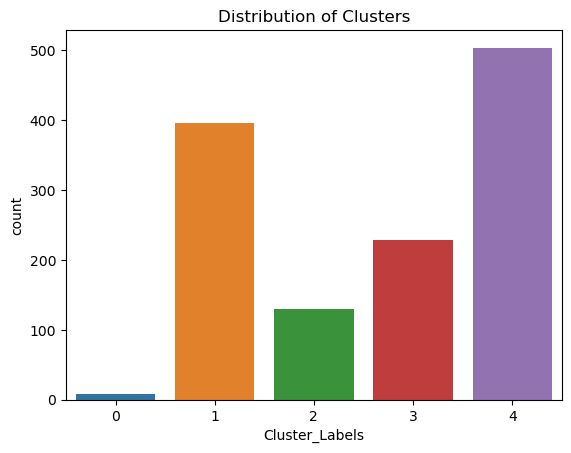

In [10]:
from sklearn.cluster import KMeans

# Specify the number of clusters
num_clusters = 5  # You can adjust this based on your task

# Perform k-means clustering
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(feature_matrix)

# Add cluster labels to the original DataFrame
nctid_eligibility['Cluster_Labels'] = cluster_labels

# Display the clusters
print("Cluster Labels:")
print(nctid_eligibility['Cluster_Labels'].value_counts())

# Visualize the clusters
sns.countplot(x='Cluster_Labels', data=nctid_eligibility)
plt.title("Distribution of Clusters")
plt.show()